# Watermark Evaluation: Paraphrasing and Back-Translation Attacks

This notebook checks whether the watermark of *Watermarking Diffusion Language
Models* (Gloaguen et al., ICLR 2026) is still detected after two attacks made
with Qwen2.5-7B-Instruct: **paraphrasing** and **back-translation**
(English → Chinese → English). Only the attacked texts that **keep the meaning
of the original** are evaluated.

| Group | Written by | Detection scores |
|---|---|---|
| Unwatermarked | LLaDA-8B, without watermark | computed here |
| Watermarked | LLaDA-8B, with watermark | computed here |
| Paraphrase | watermarked texts rewritten by Qwen2.5-7B | computed here |
| Back-translation | watermarked texts translated to Chinese and back by Qwen2.5-7B | computed here |

All groups are scored with the same local detector (the authors' code, run on
the saved text), as in the baseline detection. Nothing is written to disk: all
results are shown in the notebook.

### Structure

1. Setup
2. Configuration
3. Input data
4. Watermark detector (and its check)
5. Meaning similarity
6. Detection
7. Main results
8. Comparisons
9. Figures
10. Final checks and conclusion

### Section 1: Setup
In this initial section, we install the necessary `sentence-transformers` library used for measuring semantic similarity between original and attacked texts. We also import required libraries, mount Google Drive to access our datasets, and configure the notebook to leverage GPU acceleration if available.

## 1. Setup

We install the similarity model library, connect Google Drive (where the input
files are), and use a GPU if there is one. A GPU is not required.

### Section 2: Configuration
Here, we define all the global settings and thresholds for our experiment. This includes setting the paths to the dataset files, defining the significance levels (alpha) for the watermark detector, establishing the semantic similarity threshold (0.80) to ensure meaning is preserved, and hardcoding the reference results published in the original paper for comparison.

In [ ]:
%pip install -q sentence-transformers

In [ ]:
import json
import math
import subprocess
import sys
import textwrap
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
from google.colab import drive

drive.mount("/content/drive")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Mounted at /content/drive
Device: cuda


## 2. Configuration

- A text is detected as watermarked if its p-value is below `MAIN_ALPHA`
  (1 %, the authors' threshold). 5 % and 10 % show whether the watermark is
  gone or only weakened.
- An attacked text **keeps its meaning** if its similarity with the original
  is at least `SIM_THRESHOLD`. Statuses `no_chinese` and `not_english` are
  always removed (not real back-translations).
- `AUTHORS_FIG3` are read by eye on Fig. 3 (right) of the paper (±0.02).

### Section 3: Input Data
This section handles loading the four JSONL datasets (Unwatermarked, Watermarked, Paraphrased, and Back-translated). We perform validation checks to ensure every attacked text matches its exact original counterpart, and display descriptive statistics such as text counts and status distributions per dataset.

In [ ]:
# --- Input files -------------------------------------------------------------
DATA_DIR = Path("/content/drive/MyDrive/watermark_project")
WATERMARKED_FILE = DATA_DIR / "watermarked_600.jsonl"
UNWATERMARKED_FILE = DATA_DIR / "unwatermarked_600.jsonl"
ATTACK_FILES = {
    "Paraphrase": DATA_DIR / "paraphrased_texts_pairs.jsonl",
    "Back-translation": DATA_DIR / "backtranslated_texts_pairs.jsonl",
}

# --- Authors' detector -------------------------------------------------------
REPO_URL = "https://github.com/eth-sri/diffusion-lm-watermark.git"
REPO_DIR = Path("/content/diffusion-lm-watermark")
TOKENIZER = "GSAI-ML/LLaDA-8B-Instruct"

# --- Thresholds --------------------------------------------------------------
ALPHAS = [0.01, 0.05, 0.10]
MAIN_ALPHA = 0.01
SIM_MODEL = "sentence-transformers/all-mpnet-base-v2"
SIM_THRESHOLD = 0.80
SIM_SWEEP = [0.70, 0.75, 0.80, 0.85, 0.90]
EXCLUDED_STATUSES = {"no_chinese", "not_english"}

# --- Length analysis ---------------------------------------------------------
PREFIX_LENGTHS = [50, 100, 150, 200, 250]
LENGTH_BINS = [(0, 150), (150, 250), (250, 10**9)]
DATASET_NAMES = {"2-1_longform_qa": "Longform QA (ELI5)", "2-2_finance_qa": "Finance QA",
                 "5-1_alpacafarm": "AlpacaFarm"}

# --- Authors' results (LLaDA-8B, delta = 4, previous token as context) --------
AUTHORS_TABLE1_TPR = 0.99
AUTHORS_FIG3 = {
    "tokens":           [50,   100,  200,  300,  400],
    "Watermarked":      [0.64, 0.91, 0.98, 0.99, 1.00],
    "Back-translation": [0.39, 0.58, 0.66, 0.72, 0.76],
    "Paraphrase":       [0.34, 0.48, 0.52, 0.52, 0.55],
}

GROUPS = ["Unwatermarked", "Watermarked", "Paraphrase", "Back-translation"]
ATTACKS = list(ATTACK_FILES)
COLORS = {"Unwatermarked": "#8a8985", "Watermarked": "#2a78d6",
          "Paraphrase": "#eb6834", "Back-translation": "#1baf7a"}

## 3. Input Data

We load the four files and check that each attacked text is matched with its
own original (same line, same text).

### Section 4: Watermark Detector
We clone the official GitHub repository of the authors to import their local watermark detector. We initialize the detector using the specific hyperparameters recorded in the watermarked dataset files and define helper functions to calculate binomial p-values and evaluate shorter text prefixes.

In [ ]:
def read_jsonl(path):
    with Path(path).open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

def dataset_of(name):
    key = name.split("_batch")[0]
    return DATASET_NAMES.get(key, key)

watermarked = read_jsonl(WATERMARKED_FILE)
unwatermarked = read_jsonl(UNWATERMARKED_FILE)
attacks = {name: read_jsonl(path) for name, path in ATTACK_FILES.items()}

for name, rows in attacks.items():
    idx = [r["source_index"] for r in rows]
    assert len(set(idx)) == len(idx), f"{name}: repeated source_index"
    for r in rows:
        assert r["original"] == watermarked[r["source_index"]]["completion"], \
            f"{name}: line {r['source_index']} does not match its original"
assert [w["dataset_name"] for w in watermarked] == [u["dataset_name"] for u in unwatermarked]

print("Texts:", {"Watermarked": len(watermarked), "Unwatermarked": len(unwatermarked),
                 **{a: len(r) for a, r in attacks.items()}})
print("Every attacked text matches its original: yes")
print("Texts per dataset:", dict(Counter(dataset_of(w["dataset_name"]) for w in watermarked)))
for name, rows in attacks.items():
    print(f"Status ({name}):", dict(Counter(r["status"] for r in rows)))

Texts: {'Watermarked': 600, 'Unwatermarked': 600, 'Paraphrase': 600, 'Back-translation': 600}
Every attacked text matches its original: yes
Texts per dataset: {'Longform QA (ELI5)': 200, 'Finance QA': 200, 'AlpacaFarm': 200}
Status (Paraphrase): {'ok': 502, 'too_short': 45, 'trimmed': 53}
Status (Back-translation): {'trimmed': 366, 'ok': 223, 'no_chinese': 8, 'too_short': 2, 'not_english': 1}


## 4. Watermark Detector

We load the authors' detector (`OurWatermark.detect`, from their GitHub) with
the settings written in the watermarked file. For each text it gives:
- the **p-value**: the chance that a normal text has this many green tokens by
  luck (small = watermarked);
- the **green share**: about 0.25 without watermark, higher with it
  (the file calls it `z_score`).

To score only the first *n* tokens of a text, we reuse the token colors of
the full text (`prefix_score`): a token's color depends only on the previous
token.

### Section 4.1: Checking the Detector
To guarantee the reliability of our setup, we perform a two-step validation: we verify that the stored p-values match our mathematical calculations from the token masks, and we check that our local detector replicates the original generation-time classifications with high agreement.

In [ ]:
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
sys.path.insert(0, str(REPO_DIR / "src"))

from transformers import AutoTokenizer
from dlm_watermark.watermarks.diffusion_watermark import OurWatermark

tok = AutoTokenizer.from_pretrained(TOKENIZER, trust_remote_code=True)

WM_KEYS = ["watermark_type", "delta", "convolution_kernel", "topk", "seeding_scheme",
           "greenlist_type", "greenlist_params", "enforce_kl", "n_iter"]
wm_settings = {k: watermarked[0][k] for k in WM_KEYS}
assert all({k: w[k] for k in WM_KEYS} == wm_settings for w in watermarked)
assert wm_settings["greenlist_type"] == "bernoulli"
GAMMA = wm_settings["greenlist_params"]["gamma"]
print("Watermark settings:", wm_settings)

detector = OurWatermark(
    delta=wm_settings["delta"], enforce_kl=wm_settings["enforce_kl"],
    convolution_kernel=wm_settings["convolution_kernel"],
    greenlist_type=wm_settings["greenlist_type"], greenlist_params=wm_settings["greenlist_params"],
    topk=wm_settings["topk"], n_iter=wm_settings["n_iter"],
    seeding_scheme=wm_settings["seeding_scheme"], tokenizer=tok, device=DEVICE,
)
START_AT = max(-min(wm_settings["convolution_kernel"]), 0)


def detect_text(text):
    # Same tokenization as the authors' robustness script
    ids = tok(text, return_tensors="pt")["input_ids"]
    if ids.shape[1] <= len(wm_settings["convolution_kernel"]):
        return {"p_value": 1.0, "green_fraction": float("nan"), "n_scored": 0,
                "n_tokens": int(ids.shape[1]), "token_color": [], "mask": []}
    out = detector.detect(input_ids=ids, attention_mask=torch.ones_like(ids))
    mask = np.asarray(out["mask"], dtype=bool)
    return {"p_value": float(out["p_value"]), "green_fraction": float(out["z_score"]),
            "n_scored": int(mask.sum()), "n_tokens": int(ids.shape[1]),
            "token_color": out["token_color"], "mask": mask.tolist()}


def binomial(colors, mask):
    # (p-value, green share) over the counted tokens
    colors, mask = np.asarray(colors, dtype=float), np.asarray(mask, dtype=bool)
    n = int(mask.sum())
    if n == 0:
        return 1.0, float("nan")
    k = int(colors[mask].sum())
    return float(stats.binomtest(k, n, GAMMA, alternative="greater").pvalue), k / n


def prefix_score(colors, mask, n_tokens, n):
    # p-value of the first n tokens; None if the text is shorter than n
    if n_tokens < n:
        return None
    keep = n - START_AT
    return binomial(colors[:keep], mask[:keep])[0]

config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

configuration_llada.py:   0%|          | 0.00/12.0k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/GSAI-ML/LLaDA-8B-Instruct:
- configuration_llada.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


tokenizer_config.json:   0%|          | 0.00/51.7k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/6.10M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/747 [00:00<?, ?B/s]

Watermark settings: {'watermark_type': 'DiffusionKGW_Optimal_Gaussian', 'delta': 4.0, 'convolution_kernel': [-1], 'topk': 50, 'seeding_scheme': 'sumhash', 'greenlist_type': 'bernoulli', 'greenlist_params': {'gamma': 0.25}, 'enforce_kl': False, 'n_iter': 1}


### 4.1 Checking the detector

1. The p-values stored in the watermarked file must be recomputed exactly from
   the token colors stored in the same file.
2. Our local detector, run again on the 600 watermarked texts, must give
   almost the same decisions as the stored ones. With a wrong key or setting,
   almost no text would be detected, and the notebook stops.

The stored scores were computed on LLaDA's token ids at generation time; the
saved files only contain text, which is tokenized again. As in the baseline
detection, all groups (watermarked included) are then scored with this local
detector, so that original and attacked texts are measured the same way.

### Section 5: Meaning Similarity
We utilize the Hugging Face `all-mpnet-base-v2` model to encode both original and attacked texts. We calculate the cosine similarity between them to filter out any paraphrased or back-translated texts that failed to preserve the core meaning of the original output (similarity < 0.80).

In [ ]:
stored = [binomial(w["token_color"], w["mask"]) for w in watermarked]
p_err = max(abs(p - w["p_value"]) / max(w["p_value"], 1e-300) for (p, _), w in zip(stored, watermarked))
assert p_err < 1e-6, "the stored scores do not follow from the stored colors"
print(f"1. Stored p-values recomputed from the stored colors: max relative error {p_err:.1e}")

redetected = [detect_text(w["completion"]) for w in watermarked]
p_stored = np.array([w["p_value"] for w in watermarked])
p_redet = np.array([r["p_value"] for r in redetected])
agreement = np.mean((p_stored < MAIN_ALPHA) == (p_redet < MAIN_ALPHA))
rho = stats.spearmanr([w["z_score"] for w in watermarked], [r["green_fraction"] for r in redetected]).statistic
print(f"2. Same decision at 1%: {agreement:.1%} of the texts | correlation of green shares: {rho:.3f}")
print(f"   TPR @ 1%: stored {np.mean(p_stored < MAIN_ALPHA):.3f} | re-detected {np.mean(p_redet < MAIN_ALPHA):.3f}")
assert agreement >= 0.90 and np.mean(p_redet < MAIN_ALPHA) >= 0.5, "check the key and settings"
print("Detector validated: yes")

1. Stored p-values recomputed from the stored colors: max relative error 0.0e+00
2. Same decision at 1%: 98.8% of the texts | correlation of green shares: 0.994
   TPR @ 1%: stored 0.960 | re-detected 0.972
Detector validated: yes


**Conclusion.** In our run, the stored p-values are recomputed exactly, and our
detector takes the same decision as the stored one for 98.8 % of the texts
(correlation 0.994). It is set exactly like the authors' detector, so it can be
used on the attacked texts.

## 5. Meaning Similarity

Each text is turned into a vector by `SIM_MODEL`; two texts with the same
meaning give close vectors. The similarity (cosine) goes from 0 (unrelated) to
1 (same meaning). A text is **kept** if its similarity is at least
`SIM_THRESHOLD` and its status is valid.

### Qualitative Similarity Verification
We display example text pairs that fall right above and right below our chosen similarity threshold of 0.80. This manual inspection verifies that the automatic threshold effectively separates high-quality rewrites from those that lost important context or information.

In [ ]:
from sentence_transformers import SentenceTransformer

sim_model = SentenceTransformer(SIM_MODEL, device=DEVICE)
sim_model.max_seq_length = 512

filter_rows = []
for name, rows in attacks.items():
    a = sim_model.encode([r["original"] for r in rows], batch_size=32, normalize_embeddings=True)
    b = sim_model.encode([r["attacked"] for r in rows], batch_size=32, normalize_embeddings=True)
    for r, s in zip(rows, (a * b).sum(axis=1)):
        r["similarity"] = float(s)
        r["kept"] = bool(s >= SIM_THRESHOLD and r["status"] not in EXCLUDED_STATUSES)
    sims = np.array([r["similarity"] for r in rows])
    filter_rows.append({
        "attack": name, "texts": len(rows),
        "removed (status)": sum(r["status"] in EXCLUDED_STATUSES for r in rows),
        f"removed (similarity < {SIM_THRESHOLD})": sum(r["status"] not in EXCLUDED_STATUSES
                                                       and r["similarity"] < SIM_THRESHOLD for r in rows),
        "kept": sum(r["kept"] for r in rows),
        "median similarity": round(float(np.median(sims)), 3),
    })
display(pd.DataFrame(filter_rows).set_index("attack"))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,texts,removed (status),removed (similarity < 0.8),kept,median similarity
attack,,,,,
Paraphrase,600,0,27,573,0.931
Back-translation,600,9,30,561,0.959


For each attack, one kept and one removed text, both close to the threshold,
to check by reading that the threshold makes sense.

### Section 6: Detection
In this step, we run our validated local watermark detector on all four groups. The calculated p-values, green token fractions, lengths, and filtering statuses are combined into a single structured pandas DataFrame (`scores`) for downstream statistical analysis.

In [ ]:
def show(r, chars=400):
    print(f"  similarity {r['similarity']:.3f} | status {r['status']} | line {r['source_index']}")
    for label, key in [("ORIGINAL", "original"), ("ATTACKED", "attacked")]:
        print(textwrap.indent(textwrap.fill(f"{label}: " + r[key][:chars], 110), "    "))
    print()

for name, rows in attacks.items():
    valid = [r for r in rows if r["status"] not in EXCLUDED_STATUSES]
    above = [r for r in valid if r["similarity"] >= SIM_THRESHOLD]
    below = [r for r in valid if r["similarity"] < SIM_THRESHOLD]
    print(f"=== {name} ===")
    if above:
        print("Kept, closest to the threshold:"); show(min(above, key=lambda r: r["similarity"]))
    if below:
        print("Removed, closest to the threshold:"); show(max(below, key=lambda r: r["similarity"]))

=== Paraphrase ===
Kept, closest to the threshold:
  similarity 0.801 | status ok | line 470
    ORIGINAL: Here is the list of planets in our solar system, listed in order of their distance from the Sun:  1.
    Mercury 2. Venus 3. Earth 4. Mars 5. Jupiter 6. Saturn 7. Uranus 8. Neptune 9. Ceres (now a dwarf planet) -
    Ceres was previously considered a dwarf planet by the International Astronomical Union (IAU)  Great! Which
    planet would you like to learn more about?
    ATTACKED: Below is the sequence of the planets in our solar system, ranked by their proximity to the Sun:  1.
    Mercury 2. Venus 3. Earth 4. Mars 5. Jupiter 6. Saturn 7. Uranus 8. Neptune 9. Ceres (currently classified as
    a dwarf planet; formerly designated a dwarf planet by the IAU)  Interested in exploring one of these further?
    Which planet captures your curiosity?

Removed, closest to the threshold:
  similarity 0.800 | status ok | line 552
    ORIGINAL: Several components are needed for self-sustain

**Conclusion.** In our run, 573 paraphrased texts (95.5 %) and 561
back-translated texts (93.5 %) keep their meaning. Back-translation stays
closer to the original (median similarity 0.96 against 0.93). Near the
threshold, the kept text says the same thing with other words, while the
removed one starts to change content.

## 6. Detection

We run the local detector on the four groups (for watermarked texts, the
results of Section 4.1 are reused). All results go into one table, `scores`
(one line per group and text).

### Section 7: Main Results
We compute the main performance metrics for each group, including the True Positive Rate (TPR) at different alpha levels (1%, 5%, 10%), the Area Under the ROC Curve (AUC) against the unwatermarked baseline, and the corresponding 95% Wilson score confidence intervals.

In [ ]:
records = []
def add(group, i, w, d, extra):
    records.append({"group": group, "source_index": i, "dataset": dataset_of(w["dataset_name"]),
                    "p_value": d["p_value"], "green_fraction": d["green_fraction"],
                    "n_tokens": d["n_tokens"], "token_color": d["token_color"], "mask": d["mask"], **extra})

none = {"status": "-", "similarity": np.nan, "kept": True}
for i, (w, u) in enumerate(zip(watermarked, unwatermarked)):
    add("Unwatermarked", i, u, detect_text(u["completion"]), none)
    add("Watermarked", i, w, redetected[i], none)          # local detection (Section 4.1)
for name, rows in attacks.items():
    for r in rows:
        k = r["source_index"]
        add(name, k, watermarked[k], detect_text(r["attacked"]),
            {"status": r["status"], "similarity": r["similarity"], "kept": r["kept"]})

scores = pd.DataFrame(records)
scores["score"] = -np.log10(scores["p_value"].clip(lower=1e-300))
print(scores.groupby("group").agg(texts=("p_value", "size"), kept=("kept", "sum")))

                  texts  kept
group                        
Back-translation    600   561
Paraphrase          600   573
Unwatermarked       600   600
Watermarked         600   600


## 7. Main Results

For each group: **TPR @ α** = share of texts with a p-value below α (for
unwatermarked texts this is the false positive rate, FPR), with its 95 %
interval; **AUC** = how well the group is separated from unwatermarked texts
(1 = perfectly, 0.5 = not at all); medians of the p-value, green share and
length. "(same meaning)" = kept texts only; "(all)" = all valid texts.

### Section 7.1: Breakdown by Length and Dataset
To understand where the watermark is most vulnerable, we partition the TPR @ 1% results across different text length categories (short, medium, long) and across the three source datasets (Longform QA, Finance QA, and AlpacaFarm).

In [ ]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (c - h, c + h)

def subset(group, same_meaning=True):
    df = scores[scores.group == group]
    if group in ATTACKS:
        df = df[df.kept] if same_meaning else df[~df.status.isin(EXCLUDED_STATUSES)]
    return df

UNW = subset("Unwatermarked")

def summarize(df):
    p, n = df["p_value"].to_numpy(), len(df)
    k = int((p < MAIN_ALPHA).sum())
    lo, hi = wilson(k, n)
    out = {"texts": n, "TPR@1%": k / n, "95% CI": f"[{lo:.2f}, {hi:.2f}]"}
    for a in ALPHAS[1:]:
        out[f"TPR@{a:.0%}"] = float((p < a).mean())
    if not df["group"].eq("Unwatermarked").all():
        out["AUC"] = roc_auc_score(np.r_[np.ones(n), np.zeros(len(UNW))], np.r_[df["score"], UNW["score"]])
    out["median p-value"] = float(np.median(p))
    out["median green share"] = float(df["green_fraction"].median())
    out["median tokens"] = float(df["n_tokens"].median())
    return out

main_table = pd.DataFrame(
    {"Unwatermarked (FPR)": summarize(UNW), "Watermarked": summarize(subset("Watermarked")),
     **{f"{a} (same meaning)": summarize(subset(a)) for a in ATTACKS},
     **{f"{a} (all)": summarize(subset(a, False)) for a in ATTACKS}}).T
display(main_table.style.format(precision=3, na_rep="-"))

,texts,TPR@1%,95% CI,TPR@5%,TPR@10%,median p-value,median green share,median tokens,AUC
Unwatermarked (FPR),600,0.002,"[0.00, 0.01]",0.025,0.063,0.570,0.247,298.000,-
Watermarked,600,0.972,"[0.96, 0.98]",0.987,0.997,0.000,0.444,298.000,0.999
Paraphrase (same meaning),573,0.080,"[0.06, 0.11]",0.166,0.265,0.294,0.271,248.000,0.690
Back-translation (same meaning),561,0.351,"[0.31, 0.39]",0.597,0.736,0.028,0.315,270.000,0.922
Paraphrase (all),600,0.077,"[0.06, 0.10]",0.160,0.257,0.296,0.270,247.000,0.687
Back-translation (all),591,0.354,"[0.32, 0.39]",0.601,0.734,0.026,0.316,270.000,0.923


**Conclusion.**
- **False positives:** only 1 unwatermarked text out of 600 is flagged at 1 %
  (0.17 %): when the detector flags a text, it can be trusted.
- **Watermarked:** 583 of 600 texts are detected (97.2 %, authors: 99 %),
  with a green share of 0.44 against 0.25 without watermark.
- **Paraphrase:** only 8 % of the same-meaning texts are still detected, and
  the green share falls to 0.27, almost like a normal text: the watermark is
  nearly erased.
- **Back-translation:** 35 % still detected, and 74 % at 10 %: many texts keep
  part of the watermark, just above the 1 % threshold. It is weakened, not
  erased.
- With or without the meaning filter, the numbers barely change.

### 7.1 Breakdown by length and dataset

Longer texts are easier to detect, so we check the TPR @ 1 % by number of
tokens, then by dataset.

### Section 8.1: Attack Success Rate (ASR)
We calculate the Attack Success Rate (ASR), which represents the percentage of watermarked texts that were successfully hidden from the detector after being attacked. This metric is computed for both the semantic-filtered and unfiltered groups.

In [ ]:
def tpr_by(col):
    rows = []
    for g in GROUPS[1:]:
        for key, part in subset(g).groupby(col, observed=True):
            rows.append({"group": g, col: key, "texts": len(part),
                         "TPR@1%": float((part["p_value"] < MAIN_ALPHA).mean())})
    return pd.DataFrame(rows).pivot(index=col, columns="group", values=["texts", "TPR@1%"])

labels = [f"{lo}-{hi}" if hi < 10**9 else f"{lo}+" for lo, hi in LENGTH_BINS]
scores["length"] = pd.cut(scores["n_tokens"], bins=[b[0] for b in LENGTH_BINS] + [LENGTH_BINS[-1][1]],
                          labels=labels, right=False)
print("TPR @ 1% by number of tokens"); display(tpr_by("length").style.format(precision=3))
print("TPR @ 1% by dataset"); display(tpr_by("dataset").style.format(precision=3))

TPR @ 1% by number of tokens


TPR @ 1% by dataset


**Conclusion.** Long texts resist better (back-translation: 15 % below 150
tokens, 41 % above 250), but even for long texts the drop after the attack is
large (98.3 % of the watermarked texts above 250 tokens are detected): the
drop comes from the attack, not from length. ELI5 texts lose their watermark
the most after paraphrasing (1 %).

## 8. Comparisons

### 8.1 Before and after each attack

Each attacked text is compared with its own watermarked original. The
**Attack Success Rate (ASR)** is the share of originals detected before the
attack that are no longer detected after it (with its 95 % Wilson interval).
It is given on the same-meaning texts and on all valid texts.

### Section 8.2: Paraphrase vs. Back-translation Comparison
Using only the subset of texts that successfully preserved meaning under both attacks, we perform a direct comparison. We run the McNemar test on the discordant pairs to determine if one attack is statistically superior at removing the watermark.

In [ ]:
wm = scores[scores.group == "Watermarked"].set_index("source_index")
rows = {}
for a in ATTACKS:
    for label, same in [("same meaning", True), ("all", False)]:
        att = subset(a, same).set_index("source_index")
        before = wm.loc[att.index]
        det_b, det_a = before["p_value"] < MAIN_ALPHA, att["p_value"] < MAIN_ALPHA
        n_b, lost = int(det_b.sum()), int((det_b & ~det_a).sum())
        lo, hi = wilson(lost, n_b)
        rows[f"{a} ({label})"] = {
            "texts": len(att), "detected before": n_b, "detected after": int(det_a.sum()),
            "lost (detected -> not detected)": lost, "gained": int((~det_b & det_a).sum()),
            "ASR": lost / n_b if n_b else np.nan, "ASR 95% CI": f"[{lo:.3f}, {hi:.3f}]",
            "median green share before": before["green_fraction"].median(),
            "median green share after": att["green_fraction"].median()}
display(pd.DataFrame(rows).T.style.format(precision=3))

,texts,detected before,detected after,lost (detected -> not detected),gained,ASR,ASR 95% CI,median green share before,median green share after
Paraphrase (same meaning),573,557,46,512,1,0.919,"[0.894, 0.939]",0.445,0.271
Paraphrase (all),600,583,46,538,1,0.923,"[0.898, 0.942]",0.444,0.270
Back-translation (same meaning),561,544,197,347,0,0.638,"[0.597, 0.677]",0.445,0.315
Back-translation (all),591,574,209,365,0,0.636,"[0.596, 0.674]",0.445,0.316


**Conclusion.** Among the same-meaning texts that were detected before the
attack, 512 of 557 become undetectable after paraphrasing (ASR 91.9 %) and
347 of 544 after back-translation (ASR 63.8 %). Without the meaning filter,
the ASR is almost the same (92.3 % and 63.6 %), and both are higher than the
strongest word-level attack at ratio 0.5 (WordNet, 55.9 %).

### Section 8.3: Benchmarking Against Authors' Results
We compare our empirical detection rates on full texts and shorter prefixes directly against the figures and tables published by the original authors. This helps us assess whether our attack models are more effective than the baselines in the paper.

### 8.2 Paraphrase against back-translation

The two attacks are compared on the texts kept **for both**, so that only the
attack differs. The McNemar test uses the texts detected after one attack and
not after the other: if the attacks were equally strong, they would split
about half and half.

In [ ]:
pa, bt = (subset(a).set_index("source_index") for a in ATTACKS)
common = pa.index.intersection(bt.index)
d_pa, d_bt = pa.loc[common, "p_value"] < MAIN_ALPHA, bt.loc[common, "p_value"] < MAIN_ALPHA
only_pa, only_bt = int((d_pa & ~d_bt).sum()), int((~d_pa & d_bt).sum())
mcnemar_p = stats.binomtest(only_pa, only_pa + only_bt, 0.5).pvalue if only_pa + only_bt else 1.0
print(f"Texts kept for both attacks: {len(common)}")
print(f"TPR @ 1%: {ATTACKS[0]} {d_pa.mean():.3f} | {ATTACKS[1]} {d_bt.mean():.3f}")
print(f"Detected only after {ATTACKS[0]}: {only_pa} | only after {ATTACKS[1]}: {only_bt}")
print(f"McNemar p-value: {mcnemar_p:.3g}")

Texts kept for both attacks: 537
TPR @ 1%: Paraphrase 0.080 | Back-translation 0.352
Detected only after Paraphrase: 18 | only after Back-translation: 164
McNemar p-value: 1.15e-30


**Conclusion.** On the same 537 texts: 8 % detected after paraphrasing, 35 %
after back-translation; 18 texts against 164 in the "disagreement" cases
(McNemar p ≈ 10⁻³⁰). Paraphrasing is clearly the stronger attack.

### 8.3 Against the authors

Our TPR @ 1 % on the full texts and on the first *n* tokens (texts with at
least *n* tokens), next to the authors' values (Table 1 and Fig. 3, right).
The authors have no point at 150 and 250 tokens.

### Section 8.4: Sensitivity Analysis of Similarity Thresholds
To prove our findings are robust and not biased by an arbitrary threshold choice, we perform a sweep of the similarity filter from 0.70 to 0.90, evaluating how the TPR changes for each group.

In [ ]:
fig3 = {g: dict(zip(AUTHORS_FIG3["tokens"], AUTHORS_FIG3[g])) for g in GROUPS[1:]}

def prefix_tpr(df, n):
    ps = [prefix_score(np.asarray(c), np.asarray(m, dtype=bool), t, n)
          for c, m, t in zip(df["token_color"], df["mask"], df["n_tokens"])]
    ps = np.array([p for p in ps if p is not None])
    return (float((ps < MAIN_ALPHA).mean()) if len(ps) else np.nan), len(ps)

curve = []
for g in GROUPS:
    for n in PREFIX_LENGTHS:
        tpr, cnt = prefix_tpr(subset(g), n)
        lo, hi = wilson(round(tpr * cnt), cnt) if cnt else (np.nan, np.nan)
        curve.append({"group": g, "tokens": n, "texts": cnt, "TPR@1%": tpr, "low": lo, "high": hi,
                      "authors": fig3.get(g, {}).get(n, np.nan)})
curve = pd.DataFrame(curve)

full = pd.DataFrame({g: {"authors, Table 1": AUTHORS_TABLE1_TPR if g == "Watermarked" else np.nan,
                         "authors, Fig. 3 at 300 tokens": fig3[g][300],
                         "ours, full texts": float((subset(g)["p_value"] < MAIN_ALPHA).mean()),
                         "ours, median tokens": float(subset(g)["n_tokens"].median())}
                     for g in GROUPS[1:]}).T
print("Full texts"); display(full.style.format(precision=3, na_rep="-"))
print("First n tokens"); display(curve.pivot(index="tokens", columns="group", values=["TPR@1%", "authors"])
                                 .style.format(precision=3, na_rep="-"))

Full texts


,"authors, Table 1","authors, Fig. 3 at 300 tokens","ours, full texts","ours, median tokens"
Watermarked,0.990,0.990,0.972,298.000
Paraphrase,-,0.520,0.080,248.000
Back-translation,-,0.720,0.351,270.000


First n tokens


**Conclusion.** Without attack, our results are close to the authors' (97.7 %
against 98 % at 200 tokens). After the attacks, our texts are much less detected at
every length (at 200 tokens: 33 % against 66 % for back-translation, 8 %
against 52 % for paraphrasing), so length does not explain the gap. Possible
reasons, which our data cannot separate: our paraphrase prompt asks to change
words and structure as much as possible, and the attack model is different
(Qwen2.5-7B against GPT-5). The general conclusion is the same as in the
paper: both attacks weaken the watermark, paraphrasing more than
back-translation, and long texts resist better.

### 8.4 Effect of the similarity threshold

The same TPR @ 1 % with other thresholds of "same meaning".

### Section 9: Figures
We generate two publication-ready visualizations:
1. A histogram displaying the distribution of semantic similarity scores for both attacks relative to the selection threshold.
2. A line plot comparing detection rates (TPR @ 1%) across different text lengths for our results versus the authors' reference curves.

In [ ]:
sweep = []
for t in SIM_SWEEP:
    row = {"threshold": t}
    for a in ATTACKS:
        df = scores[(scores.group == a) & (~scores.status.isin(EXCLUDED_STATUSES)) & (scores.similarity >= t)]
        row[f"{a}: texts"] = len(df)
        row[f"{a}: TPR@1%"] = float((df["p_value"] < MAIN_ALPHA).mean()) if len(df) else np.nan
    sweep.append(row)
display(pd.DataFrame(sweep).set_index("threshold").style.format(precision=3))

,Paraphrase: texts,Paraphrase: TPR@1%,Back-translation: texts,Back-translation: TPR@1%
threshold,,,,
0.700000,597,0.077,583,0.352
0.750000,593,0.078,573,0.351
0.800000,573,0.080,561,0.351
0.850000,528,0.085,537,0.350
0.900000,419,0.093,492,0.354


**Conclusion.** Back-translation stays at about 35 % whatever the threshold;
paraphrasing moves only from 7.7 % to 9.3 %. Our conclusions do not depend on
the chosen threshold.

## 9. Figures

1. Similarity of the attacked texts with their original (with the threshold).
2. TPR @ 1 % against the number of tokens: ours (solid, 95 % interval) and the
   authors' (dashed).

### Section 10: Final Checks & Conclusion
We run a series of integrity assertions to ensure that our dataset dimensions and subsets are mathematically consistent and free of duplicate entries. Lastly, we print a comprehensive text-based summary of our experimental findings and overall conclusions.

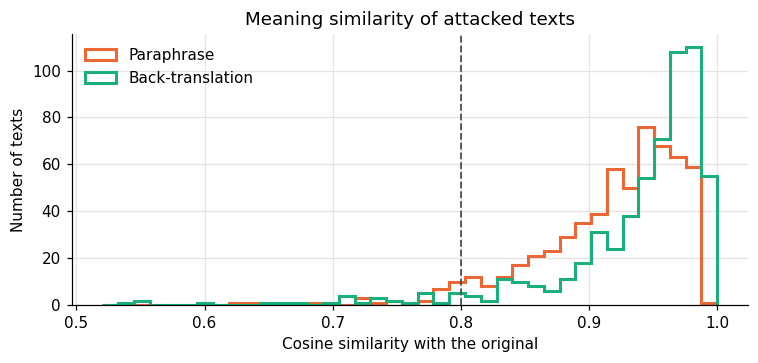

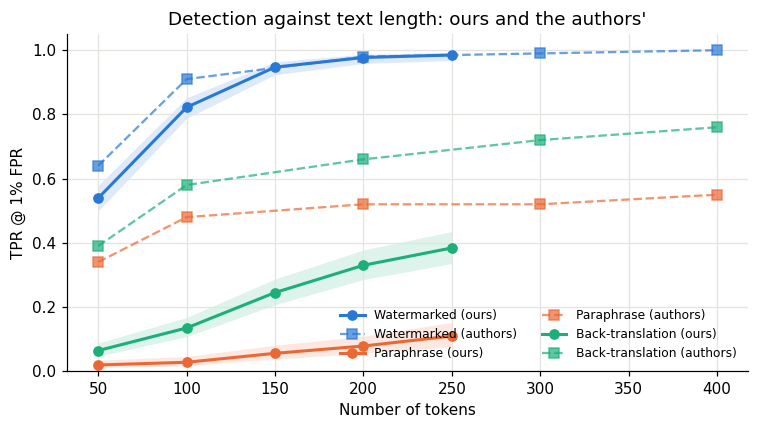

In [ ]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "legend.frameon": False})

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(min(scores.similarity.min(), SIM_SWEEP[0]) - 0.02, 1, 40)
for a in ATTACKS:
    df = scores[(scores.group == a) & (~scores.status.isin(EXCLUDED_STATUSES))]
    ax.hist(df.similarity, bins=bins, histtype="step", linewidth=2, color=COLORS[a], label=a)
ax.axvline(SIM_THRESHOLD, color="#52514e", linestyle="--", linewidth=1.2)
ax.set(xlabel="Cosine similarity with the original", ylabel="Number of texts",
       title="Meaning similarity of attacked texts")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for g in GROUPS[1:]:
    c = curve[curve.group == g]
    ax.plot(c.tokens, c["TPR@1%"], marker="o", linewidth=2, color=COLORS[g], label=f"{g} (ours)")
    ax.fill_between(c.tokens, c.low, c.high, color=COLORS[g], alpha=0.15, linewidth=0)
    ax.plot(AUTHORS_FIG3["tokens"], AUTHORS_FIG3[g], marker="s", linestyle="--", linewidth=1.5,
            color=COLORS[g], alpha=0.7, label=f"{g} (authors)")
ax.set(xlabel="Number of tokens", ylabel="TPR @ 1% FPR", ylim=(0, 1.05),
       title="Detection against text length: ours and the authors'")
ax.legend(loc="lower right", ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

## 10. Final Checks and Conclusion

In [ ]:
assert len(watermarked) == len(unwatermarked) == 600 and all(len(r) == 600 for r in attacks.values())
kept = scores[scores.group.isin(ATTACKS) & scores.kept]
assert (kept.similarity >= SIM_THRESHOLD).all() and not kept.status.isin(EXCLUDED_STATUSES).any()
assert scores.groupby("group").source_index.apply(lambda s: s.is_unique).all()
k_fp = int((UNW["p_value"] < MAIN_ALPHA).sum())
lo, hi = wilson(k_fp, len(UNW))
assert lo <= MAIN_ALPHA, "clearly more than 1% false positives: check the detector"
print("600 texts per group, kept texts valid, no text counted twice: yes")
print(f"False positives at 1%: {k_fp}/600 = {k_fp/600:.2%} (95% CI [{lo:.3f}, {hi:.3f}]), not above 1%: yes")

print()
tpr = {g: float((subset(g)["p_value"] < MAIN_ALPHA).mean()) for g in GROUPS[1:]}
print(f"- Watermarked: TPR @ 1% = {tpr['Watermarked']:.1%} (authors: {AUTHORS_TABLE1_TPR:.0%}).")
for a in ATTACKS:
    print(f"- {a}: {len(subset(a))}/600 texts keep the meaning; TPR @ 1% = {tpr[a]:.1%} "
          f"(authors at 300 tokens: about {fig3[a][300]:.0%}).")
print(f"- Stronger attack: {min(ATTACKS, key=tpr.get)} (McNemar p = {mcnemar_p:.2g}).")

600 texts per group, kept texts valid, no text counted twice: yes
False positives at 1%: 1/600 = 0.17% (95% CI [0.000, 0.009]), not above 1%: yes

- Watermarked: TPR @ 1% = 97.2% (authors: 99%).
- Paraphrase: 573/600 texts keep the meaning; TPR @ 1% = 8.0% (authors at 300 tokens: about 52%).
- Back-translation: 561/600 texts keep the meaning; TPR @ 1% = 35.1% (authors at 300 tokens: about 72%).
- Stronger attack: Paraphrase (McNemar p = 1.2e-30).


**Overall conclusion.**
- The detector is reliable: almost no false positives (0.17 %), and almost
  all watermarked texts are detected, close to the authors' 99 %.
- Both attacks keep the meaning in more than 93 % of the cases and strongly
  weaken the watermark: after paraphrasing only 8 % of the texts are still
  detected (watermark nearly erased), after back-translation 35 % (watermark
  weakened but often still present).
- Paraphrasing is clearly the stronger attack.
- Like the authors, we find that both attacks weaken the watermark,
  paraphrasing more than back-translation, and that longer texts resist
  better. Our attacks are however stronger than theirs at every length: in
  our setting, with a free model, most texts become undetectable while
  keeping their meaning.
- These conclusions hold with or without the meaning filter and for all the
  similarity thresholds tested (0.70 to 0.90).